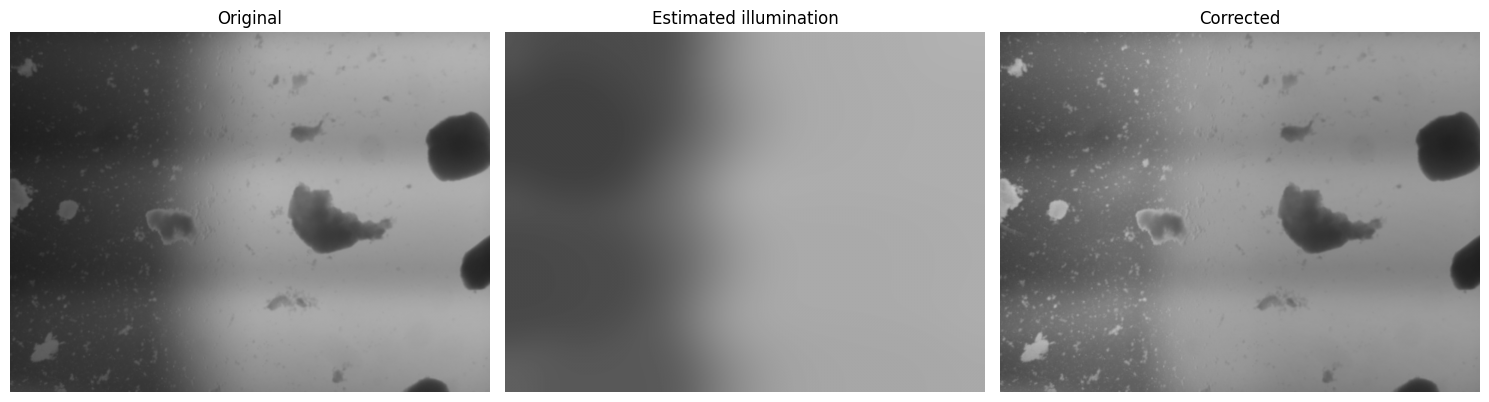

Saved to: C:\Users\chenr\OneDrive\文档\ChatGPT\DSC180A\preprocessing_2023_trial
Pixels reaching the amplification limit: 19.81%
Pixels exceeding 255 before clipping: 0.00%


In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Input image
input_path = Path(
    r"C:\OneDrive_local_\Desktop\realtime-organoid-XYZ"
    r"\High_quality_image_23&24\High_quality_image_2023"
    r"\01_12_2023_17_45_09p6.png"
)

output_dir = Path(
    r"C:\Users\chenr\OneDrive\文档\ChatGPT\DSC180A"
    r"\preprocessing_2023_trial"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Starting parameters for this image; adjust after visual inspection.
kernel_ratio = 0.35   # Background-estimation kernel / shorter image dimension
smooth_ratio = 0.05   # Smooth the estimated background
max_gain = 2.0        # Maximum amplification in dark regions


def save_png(path, array):
    success, encoded = cv2.imencode(".png", array)
    if not success:
        raise IOError(f"Failed to encode {path}")
    path.write_bytes(encoded.tobytes())


# Read with Unicode path support.
img = cv2.imdecode(
    np.frombuffer(input_path.read_bytes(), dtype=np.uint8),
    cv2.IMREAD_COLOR,
)
if img is None:
    raise ValueError(f"Cannot read {input_path}")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
height, width = gray.shape

# Work on a smaller copy ONLY to estimate illumination.
scale = min(1.0, 400 / max(height, width))
small = cv2.resize(
    gray,
    (round(width * scale), round(height * scale)),
    interpolation=cv2.INTER_AREA,
)

# Suppress isolated bright/dark specks in the estimation copy.
small_filtered = cv2.medianBlur(small, 5)

# Closing fills dark structures to approximate the bright background.
# This is an estimate, not an organoid segmentation mask.
kernel_size = max(3, round(min(small.shape) * kernel_ratio))
if kernel_size % 2 == 0:
    kernel_size += 1

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (kernel_size, kernel_size)
)

background_small = cv2.morphologyEx(
    small_filtered,
    cv2.MORPH_CLOSE,
    kernel,
    borderType=cv2.BORDER_REFLECT_101,
).astype(np.float32)

sigma = max(1.0, min(small.shape) * smooth_ratio)
background_small = cv2.GaussianBlur(
    background_small,
    (0, 0),
    sigmaX=sigma,
    sigmaY=sigma,
    borderType=cv2.BORDER_REFLECT_101,
)

background = cv2.resize(
    background_small,
    (width, height),
    interpolation=cv2.INTER_LINEAR,
)

# Normalize illumination while limiting dark-region amplification.
target = float(np.median(background))
raw_gain = target / np.maximum(background, 1.0)
gain = np.clip(raw_gain, 1 / max_gain, max_gain)

corrected_float = gray.astype(np.float32) * gain
corrected = np.clip(corrected_float, 0, 255).astype(np.uint8)

# Save separate outputs; leave the source unchanged.
save_png(output_dir / f"{input_path.stem}_corrected.png", corrected)
save_png(
    output_dir / f"{input_path.stem}_estimated_background.png",
    np.clip(background, 0, 255).astype(np.uint8),
)

# Compare using the SAME display range.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, image, title in zip(
    axes,
    [gray, background, corrected],
    ["Original", "Estimated illumination", "Corrected"],
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    output_dir / f"{input_path.stem}_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

print(f"Saved to: {output_dir}")
print(f"Pixels reaching the amplification limit: "
      f"{100 * np.mean(raw_gain > max_gain):.2f}%")
print(f"Pixels exceeding 255 before clipping: "
      f"{100 * np.mean(corrected_float > 255):.2f}%")